In [5]:
# !uv add arviz
# !uv add pymc
# !uv add netCDF4
# !uv add pyarrow

### if there are problems with the pymce Model widget use
!uv remove  ipywidgets jupyterlab_widgets
!uv add ipywidgets>=8.0.0 jupyterlab_widgets

Resolved 176 packages in 6.46s                                       
Prepared 1 package in 1.47s                                              m            ⠧ Preparing packages... (0/1)                                                   
Uninstalled 5 packages in 297ms
░░░░░░░░░░░░░░░░░░░░ [0/1] Installing wheels...                                 warning: Failed to hardlink files; falling back to full copy. This may lead to degraded performance.
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 1 package in 18ms.0.1 (from file:///workspaces/aml
 ~ aml-working-paper==0.0.1 (from file:///workspaces/aml-working-paper)
 - fg-data-profiling==4.20.0
 - ipywidgets==8.1.9
 - jupyterlab-widgets==3.0.17
 - shapely==2.2.0
Resolved 178 packages in 437ms                                       
Prepared 1 package in 83

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib


import pymc as pm
import arviz as az
from aml_working_paper.data.preprocess import preprocess_data
from aml_working_paper.models.bayes_hmm import build_hmm_model
from aml_working_paper.models.labelswitch import labelswitch
from aml_working_paper.routing.routing import *
from aml_working_paper.config import RAW_DATA_DIR, PROCESSED_DATA_DIR, MODELS_DIR


### 1. Get the synthetic data and preprocess it

In [7]:
df_aml = pd.read_csv("{}/synthetic_df_aml.csv".format(RAW_DATA_DIR))

In [8]:
train_df, val_df, test_df, train_sequences, val_sequences, test_sequences, scaler = preprocess_data(df_aml)

### 2. Build the HMM 

In [9]:
model = build_hmm_model(train_sequences)

### 3. Train it

#### 3.1 Simple quick model for demonstration purposes

In [10]:
### The model configuration should take less than a minute to run in a 8GB CPU and 16RAM computer
### If it takes more, please restart the notebook. You should also be able to see the Pymc widget of the model running
### If not, please go to the top of this notebook and run the respective commands
with model:
    demo_test = pm.sample(draws=5, tune=5, chains=4, cores=4, target_accept=0.9, random_seed=42)

Only 5 samples per chain. Reliable r-hat and ESS diagnostics require longer chains for accurate estimate.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [pi, current, mu, sigma]


Output()

Sampling 4 chains for 5 tune and 5 draw iterations (20 + 20 draws total) took 3 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.
The number of samples is too small to check convergence reliably.


In [ ]:
### The lower de divergence, the better. (Without label switch)
### Divergence increases when the posterior has difficult regions to investigate and the model could skip these. Therefore, introducing bias
print("Divergences:", demo_test.sample_stats["diverging"].sum().item() )

Divergences: 2


In [ ]:
### Bayesian Fraction of Missing Information. How well is the updating done wehn the model is moving across regions of the posterior distribution. (Without label switch)
### The higher, the better
print("\nBFMI:", az.bfmi(demo_test) )


BFMI: <xarray.DataTree 'sample_stats'>
Group: /sample_stats
    Dimensions:  (chain: 4)
    Coordinates:
      * chain    (chain) int64 32B 0 1 2 3
    Data variables:
        energy   (chain) float64 32B 0.6799 0.5763 0.9998 0.5384


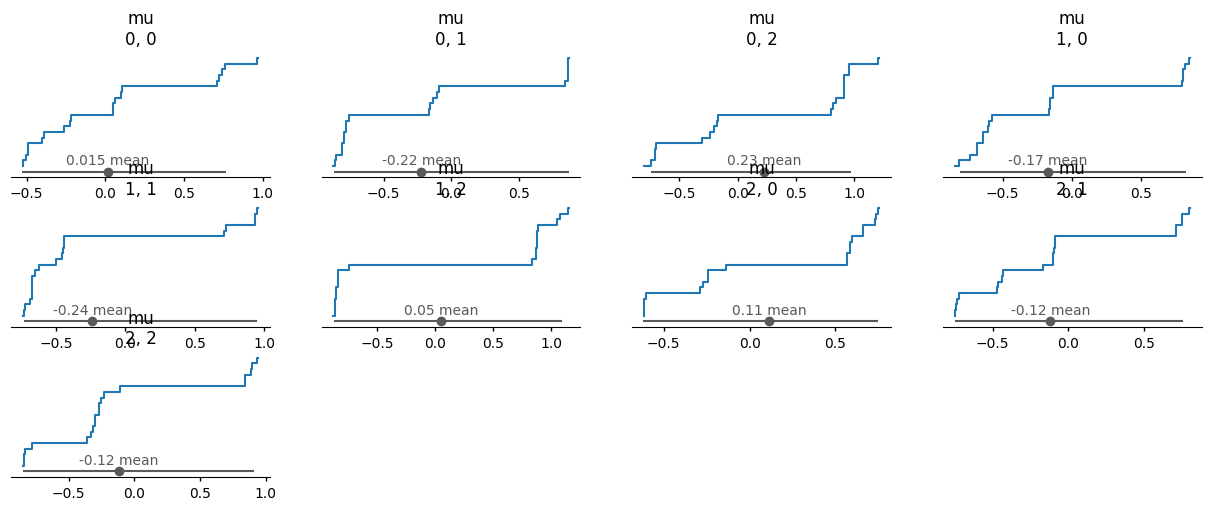

In [ ]:
### Graph the marginal posterior distributions of the mu parameter (Without label switch)
### How possible or compatible are the emissions of the samples obtained
### since this is a demo (and label switch has not been applied), the graphs turn out incomplete
az.plot_dist(demo_test, var_names=["mu"])

In [ ]:
### Apply label switch to match the labels within the chains. 
aligned_trace_demo, permutations_demo = labelswitch(demo_test)

In [ ]:
### Get the multiple possible samples of the posterior distribution for the parameters. (With label switch)
### mean: posterior mean of the parameter
### sd: standard deviation of the posterior. uncertainty about the parameter
### r_hat: convergence between chains. Closer to 1 the better.
print(az.summary(aligned_trace_demo,var_names=["pi", "current", "mu", "sigma"],round_to=3))

                mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  \
pi[0]          0.323  0.201     0.097     0.579    19.266    19.266  4.957   
pi[1]          0.362  0.166     0.102     0.576    19.266    19.266  3.536   
pi[2]          0.315  0.161     0.104     0.539    19.266    19.266  4.418   
current[0, 0]  0.712  0.213     0.242     0.879    19.266    19.266  4.881   
current[0, 1]  0.083  0.054     0.034     0.181    19.266    19.266  5.103   
current[0, 2]  0.206  0.185     0.065     0.638    19.266    19.266  3.335   
current[1, 0]  0.229  0.178     0.064     0.582    19.266    19.266  2.569   
current[1, 1]  0.541  0.232     0.301     0.876    19.266    19.266  2.569   
current[1, 2]  0.229  0.128     0.060     0.395    19.266    19.266  2.160   
current[2, 0]  0.196  0.124     0.113     0.389    19.266    19.266  1.903   
current[2, 1]  0.488  0.138     0.387     0.653    19.266    19.266  1.669   
current[2, 2]  0.316  0.126     0.149     0.497    19.266    19.

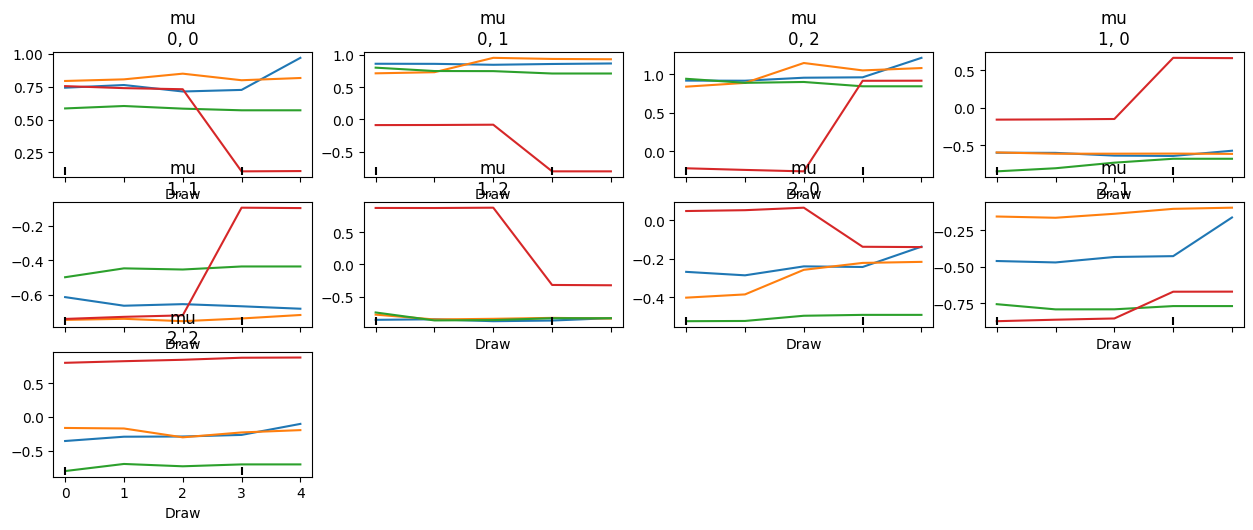

In [ ]:
### Plot how the chains went through the parameters' values. How the chains were mixed
az.plot_trace(aligned_trace_demo,var_names=["mu"])

#### 3.2 Different configuration models

In [19]:
with model:
    trace_test = pm.sample(draws=1000, tune=1000, chains=6, cores=6, target_accept=0.9, random_seed=42 )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (6 chains in 6 jobs)
NUTS: [pi, current, mu, sigma]


Output()

Sampling 6 chains for 1_000 tune and 1_000 draw iterations (6_000 + 6_000 draws total) took 908 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


#### 3.3 Metrics

In [20]:
### Get the multiple possible samples of the posterior distribution for the parameters. 
print(az.summary(trace_test, var_names=["pi", "current", "mu", "sigma"], round_to=3 ) )

                mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  \
pi[0]          0.232  0.258     0.020     0.811     7.581     9.688  2.247   
pi[1]          0.334  0.327     0.020     0.841     7.565    25.037  2.259   
pi[2]          0.433  0.355     0.020     0.849     8.249    25.138  1.956   
current[0, 0]  0.761  0.080     0.668     0.877     7.850     9.689  2.109   
current[0, 1]  0.128  0.050     0.023     0.173     8.722     9.707  1.822   
current[0, 2]  0.110  0.066     0.011     0.171     8.774     9.720  1.806   
current[1, 0]  0.125  0.054     0.011     0.171     8.801     9.680  1.806   
current[1, 1]  0.793  0.081     0.671     0.881     7.529    24.848  2.279   
current[1, 2]  0.082  0.064     0.011     0.169     7.022     9.693  2.716   
current[2, 0]  0.097  0.059     0.011     0.169     6.994     9.895  2.750   
current[2, 1]  0.079  0.064     0.010     0.164     7.417    25.570  2.358   
current[2, 2]  0.824  0.068     0.678     0.883     7.854     9.

In [21]:
print("Divergences:",trace_test.sample_stats["diverging"].sum().item() )

Divergences: 0


In [22]:
print("\nBFMI:", az.bfmi(trace_test) )


BFMI: <xarray.DataTree 'sample_stats'>
Group: /sample_stats
    Dimensions:  (chain: 6)
    Coordinates:
      * chain    (chain) int64 48B 0 1 2 3 4 5
    Data variables:
        energy   (chain) float64 48B 1.099 1.103 0.9885 0.9766 1.064 1.079


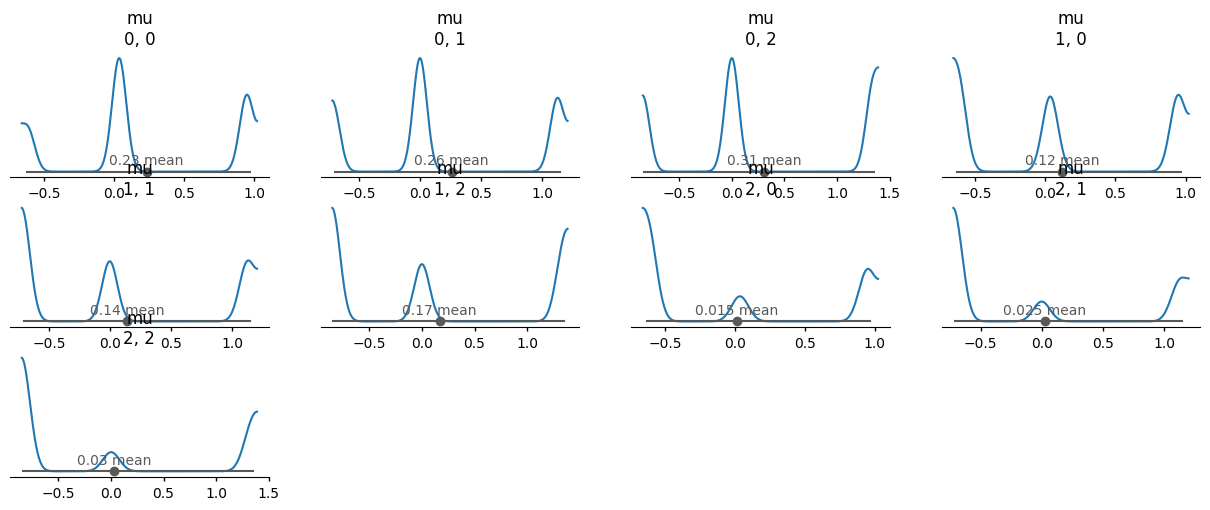

In [23]:
az.plot_dist(trace_test, var_names=["mu"])

In [24]:
aligned_trace, permutations = labelswitch(trace_test)

In [25]:
print(az.summary(aligned_trace,var_names=["pi", "current", "mu", "sigma"],round_to=3))

                mean     sd  eti89_lb  eti89_ub   ess_bulk  ess_tail  r_hat  \
pi[0]          0.042  0.023     0.012     0.083   6984.178  4183.590  1.000   
pi[1]          0.783  0.056     0.688     0.867   8267.525  4943.121  1.000   
pi[2]          0.175  0.053     0.096     0.265   8465.837  5170.519  1.001   
current[0, 0]  0.821  0.010     0.804     0.837   8621.950  5076.422  1.001   
current[0, 1]  0.025  0.004     0.018     0.032   6765.748  4425.483  1.001   
current[0, 2]  0.154  0.010     0.138     0.171   8761.363  4956.907  1.001   
current[1, 0]  0.012  0.003     0.008     0.017   6648.002  4106.579  1.002   
current[1, 1]  0.873  0.008     0.861     0.885   6371.941  5162.221  1.002   
current[1, 2]  0.114  0.008     0.103     0.127   6298.709  4979.479  1.002   
current[2, 0]  0.161  0.010     0.146     0.178   8555.284  4551.636  1.000   
current[2, 1]  0.154  0.010     0.138     0.171   9073.799  4742.779  1.000   
current[2, 2]  0.684  0.014     0.663     0.706   84

- r_hat: between 1.000 and 1.002, the chains show very good consistency.

- ess_bulk: it has high values which are effective sample size for estimating the central regions of the posterior distributions.

- mcse: It is close to zero so the Monte Carlo standard error is small

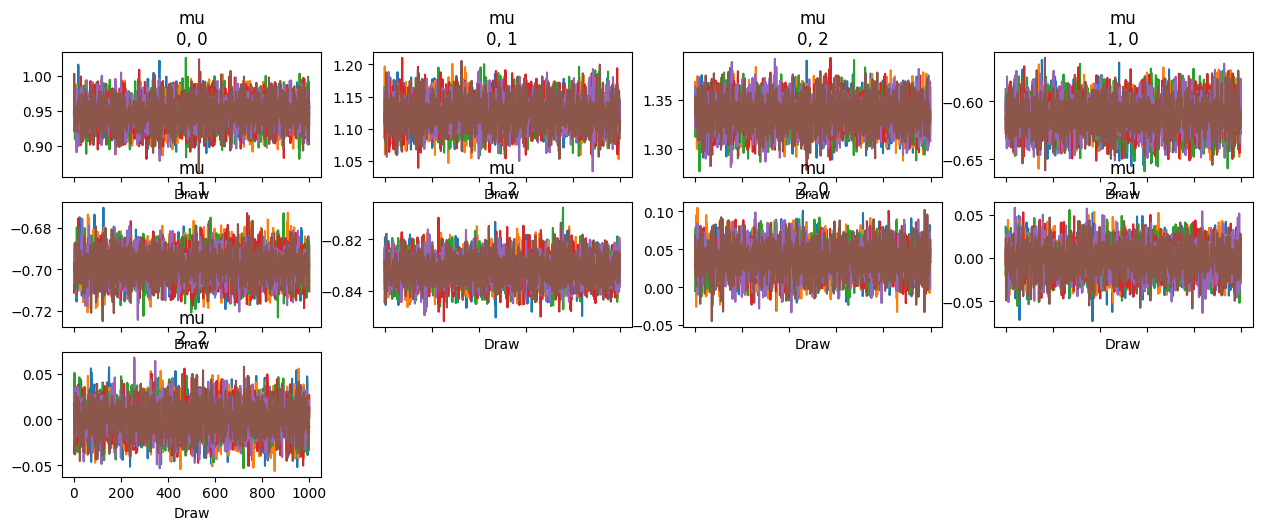

In [26]:
az.plot_trace(aligned_trace,var_names=["mu"])

- The chains appear to be mixed properly.

- There are no clear trends

- The samples are stable and concentrated in different regions.

In [ ]:
az.plot_dist(trace_test, var_names=["mu"])

### 4. Save important data

### Model

In [ ]:
aligned_trace.to_netcdf("{}/bayes_hmm_aligned_posterirors.nc".format(MODELS_DIR))

### Data

In [29]:
np.save("{}/train_account_ids.npy".format(PROCESSED_DATA_DIR), train_df["account_id"].unique())

np.save("{}/val_account_ids.npy".format(PROCESSED_DATA_DIR), val_df["account_id"].unique())

np.save( "{}/test_account_ids.npy".format(PROCESSED_DATA_DIR), test_df["account_id"].unique())

### Scaler

In [30]:
joblib.dump(scaler, "{}/hmm_scaler.joblib".format(MODELS_DIR))

['/workspaces/aml-working-paper/models/hmm_scaler.joblib']